# Лабораторная работа №1. Метод обратного распространения ошибки

**Студент:** Ермолаев Д.А.  
**Группа:** 3825М1ФИ2

## Цель

Изучить метод обратного распространения ошибки на двухслойной полносвязной сети с одним скрытым слоем и применить его к классификации цифр MNIST.

| параметр | значение |
|---|---|
| скрытые нейроны $s$ | 300 |
| скорость обучения $\eta$ | 0.1 |
| размер пачки | 64 |
| число эпох | 20 |
| активация скрытого слоя | ReLU |
| активация выхода | softmax |
| функция ошибки | кросс-энтропия |


## Сеть

Изображение MNIST — матрица $28 \times 28$. Разворачиваем её в вектор $x \in \mathbb{R}^{N}$, $N = 784$. На входном слое функции активации нет.

Скрытый слой, $s = 300$ нейронов:

$$
f_s = \sum_{i=0}^{N-1} w^{(1)}_{si} x_i + b^{(1)}_s, \qquad
v_s = \mathrm{ReLU}(f_s) =
\begin{cases}
f_s, & f_s > 0, \\
0, & f_s \le 0.
\end{cases}
$$

На скрытом слое ставим ReLU. У сигмоиды при большом по модулю входе производная почти нулевая, и градиент затухает. У ReLU на положительной полуоси производная равна 1. Если $f_s \le 0$ на всех примерах, локальный градиент этого нейрона нулевой и его вес не меняется.

Выходной слой, $M = 10$ классов:

$$
g_j = \sum_{s} w^{(2)}_{js} v_s + b^{(2)}_j, \qquad
u_j = \frac{e^{g_j}}{\sum_{i=1}^{M} e^{g_i}}.
$$

Все $u_j > 0$ и $\sum_j u_j = 1$.

## Функция ошибки

Метку записываем как one-hot: $y_j = 1$ только у верного класса. Для одного примера кросс-энтропия равна

$$
E = -\sum_{j=1}^{M} y_j \ln u_j = -\ln u_c,
$$

где $c$ — номер верного класса. На пачке из $B$ примеров берём среднее $E$.

## Градиенты

Подставляем softmax в кросс-энтропию. Пусть $Z = \sum_i e^{g_i}$. Тогда $u_j = e^{g_j}/Z$ и, так как $\sum_j y_j = 1$,

$$
E = -\sum_j y_j g_j + \ln Z.
$$

Производная по логиту класса $k$:

$$
\frac{\partial E}{\partial g_k} = -y_k + u_k.
$$

Локальная ошибка выходного слоя:

$$
\delta^{(2)}_j = u_j - y_j.
$$

Производная по весу — ошибка на конце связи, умноженная на значение нейрона в её начале:

$$
\frac{\partial E}{\partial w^{(2)}_{js}} = \delta^{(2)}_j\, v_s, \qquad
\frac{\partial E}{\partial b^{(2)}_j} = \delta^{(2)}_j.
$$

На скрытый слой ошибка приходит через веса второго слоя и умножается на производную ReLU, $\mathrm{ReLU}'(f_s) = 1$ при $f_s > 0$ и $0$ иначе:

$$
\delta^{(1)}_s = \mathrm{ReLU}'(f_s)\,\sum_j w^{(2)}_{js}\,\delta^{(2)}_j,
$$

$$
\frac{\partial E}{\partial w^{(1)}_{si}} = \delta^{(1)}_s\, x_i, \qquad
\frac{\partial E}{\partial b^{(1)}_s} = \delta^{(1)}_s.
$$

Веса сдвигаем против градиента:

$$
w \leftarrow w - \eta\,\nabla E(w), \qquad \eta = 0.1.
$$

Градиент усредняем по пачке из $B = 64$ примеров, потому что и $E$ усреднена по пачке. Перед каждой эпохой перемешиваем обучающую выборку. Эпох — 20.

## Начальные веса и вход

Слишком большие начальные веса загоняют ReLU в ноль, слишком маленькие оставляют обучение около начала координат. Веса скрытого слоя берём из $\mathcal{N}(0, \sqrt{2/N})$, веса выходного слоя — из $\mathcal{N}(0, \sqrt{1/s})$, смещения ставим равными нулю.

Пиксели делим на 255 и вычитаем среднее изображение обучающей выборки, чтобы средний вход был около нуля. Из теста вычитаем это же среднее.


## Загрузка MNIST

Если файлов ещё нет, скачиваем IDX-архив в `data/mnist` рядом с ноутбуком.


In [1]:
import gzip
import os
import struct
import time
import urllib.request

import matplotlib.pyplot as plt
import numpy as np

DATA_DIR = os.path.join("data", "mnist")
MNIST_FILES = {
    "train-images-idx3-ubyte.gz": "https://ossci-datasets.s3.amazonaws.com/mnist/train-images-idx3-ubyte.gz",
    "train-labels-idx1-ubyte.gz": "https://ossci-datasets.s3.amazonaws.com/mnist/train-labels-idx1-ubyte.gz",
    "t10k-images-idx3-ubyte.gz": "https://ossci-datasets.s3.amazonaws.com/mnist/t10k-images-idx3-ubyte.gz",
    "t10k-labels-idx1-ubyte.gz": "https://ossci-datasets.s3.amazonaws.com/mnist/t10k-labels-idx1-ubyte.gz",
}


def ensure_mnist(data_dir=DATA_DIR):
    os.makedirs(data_dir, exist_ok=True)
    for name, url in MNIST_FILES.items():
        path = os.path.join(data_dir, name)
        if not os.path.exists(path):
            print(f"скачиваю {name}")
            urllib.request.urlretrieve(url, path)


def load_idx_images(path):
    with gzip.open(path, "rb") as f:
        magic, n, rows, cols = struct.unpack(">IIII", f.read(16))
        if magic != 2051:
            raise ValueError(f"неверный заголовок изображений: {magic}")
        data = np.frombuffer(f.read(), dtype=np.uint8)
        return data.reshape(n, rows, cols)


def load_idx_labels(path):
    with gzip.open(path, "rb") as f:
        magic, n = struct.unpack(">II", f.read(8))
        if magic != 2049:
            raise ValueError(f"неверный заголовок меток: {magic}")
        return np.frombuffer(f.read(), dtype=np.uint8).copy()


ensure_mnist()
train_images = load_idx_images(os.path.join(DATA_DIR, "train-images-idx3-ubyte.gz"))
train_labels = load_idx_labels(os.path.join(DATA_DIR, "train-labels-idx1-ubyte.gz"))
test_images = load_idx_images(os.path.join(DATA_DIR, "t10k-images-idx3-ubyte.gz"))
test_labels = load_idx_labels(os.path.join(DATA_DIR, "t10k-labels-idx1-ubyte.gz"))

print("train images:", train_images.shape, train_images.dtype)
print("train labels:", train_labels.shape, train_labels.dtype)
print("test images:", test_images.shape, test_images.dtype)
print("test labels:", test_labels.shape, test_labels.dtype)
print("одно изображение:", train_images[0].shape, "метка:", int(train_labels[0]))


скачиваю train-images-idx3-ubyte.gz


скачиваю train-labels-idx1-ubyte.gz


скачиваю t10k-images-idx3-ubyte.gz


скачиваю t10k-labels-idx1-ubyte.gz


train images: (60000, 28, 28) uint8
train labels: (60000,) uint8
test images: (10000, 28, 28) uint8
test labels: (10000,) uint8
одно изображение: (28, 28) метка: 5


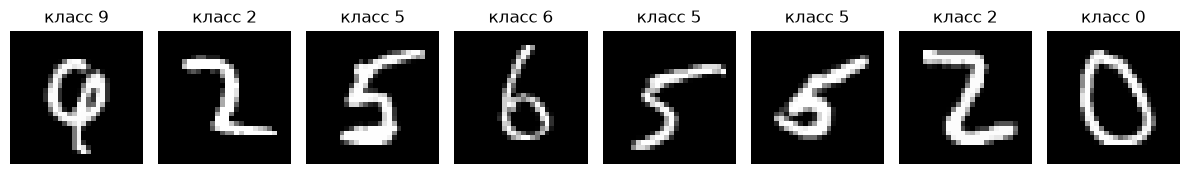

In [2]:
rng_view = np.random.default_rng(1)
show_idx = rng_view.choice(len(train_images), size=8, replace=False)

fig, axes = plt.subplots(1, 8, figsize=(12, 2))
for ax, i in zip(axes, show_idx):
    ax.imshow(train_images[i], cmap="gray")
    ax.set_title(f"класс {int(train_labels[i])}")
    ax.axis("off")
plt.tight_layout()
plt.show()


## Предобработка

Пиксель из $\{0, \ldots, 255\}$ переводим в $[0, 1]$ и вычитаем среднее по обучающим изображениям. Вектор входа — строка длины 784.


In [3]:
X_train = train_images.reshape(len(train_images), -1).astype(np.float32) / 255.0
X_test = test_images.reshape(len(test_images), -1).astype(np.float32) / 255.0
y_train = train_labels.astype(np.int64)
y_test = test_labels.astype(np.int64)

train_mean = X_train.mean(axis=0, keepdims=True)
X_train -= train_mean
X_test -= train_mean

print("X_train", X_train.shape, "y_train", y_train.shape)
print("X_test", X_test.shape, "y_test", y_test.shape)
print("среднее входа после нормировки: %.3e" % float(X_train.mean()))


X_train (60000, 784) y_train (60000,)
X_test (10000, 784) y_test (10000,)
среднее входа после нормировки: -2.189e-06


## Прямой и обратный проход

Для пачки $X$ размера $B \times 784$ матрица $W^{(1)}$ имеет размер $784 \times s$, $W^{(2)}$ — размер $s \times 10$. Строка `f = X @ W1 + b1` — это $f_s$.

Перед экспонентой вычитаем из логитов максимум по классам. Softmax от этого не меняется, а `float32` не переполняется.

Поскольку $E$ — среднее по пачке, локальную ошибку тоже делим на $B$:

$$
\delta^{(2)} = \frac{1}{B}(U - Y).
$$


In [4]:
def relu(f):
    return np.maximum(f, 0.0)


def softmax(g):
    shifted = g - g.max(axis=1, keepdims=True)
    exp_g = np.exp(shifted)
    return exp_g / exp_g.sum(axis=1, keepdims=True)


def forward(X, W1, b1, W2, b2):
    f = X @ W1 + b1
    v = relu(f)
    g = v @ W2 + b2
    u = softmax(g)
    return f, v, g, u


def cross_entropy(u, y):
    # E = -ln u_c, среднее по пачке. Слагаемые чужих классов равны нулю.
    picked = u[np.arange(len(y)), y]
    return -np.mean(np.log(picked + 1e-12))


def classification_error(u, y):
    return float(np.mean(u.argmax(axis=1) != y))


def backward(X, y, f, v, u, W2):
    # delta2_j = (u_j - y_j) / B
    batch = X.shape[0]
    delta2 = u.copy()
    delta2[np.arange(batch), y] -= 1.0
    delta2 /= batch

    dW2 = v.T @ delta2
    db2 = delta2.sum(axis=0)

    # delta1_s = ReLU'(f_s) * sum_j w2_js * delta2_j
    dv = delta2 @ W2.T
    delta1 = dv * (f > 0.0)
    dW1 = X.T @ delta1
    db1 = delta1.sum(axis=0)
    return dW1, db1, dW2, db2


## Проверка градиента

На маленькой сети сравниваем формулы с центральной разностью по нескольким координатам весов. Для обучения разности не используем: по каждому весу пришлось бы считать сеть заново.


In [5]:
def numerical_gradient_check(seed=0, eps=1e-5):
    rng = np.random.default_rng(seed)
    X = rng.normal(size=(4, 6)).astype(np.float64)
    y = np.array([0, 2, 1, 2])
    W1 = rng.normal(scale=0.3, size=(6, 5)).astype(np.float64)
    b1 = np.zeros(5, dtype=np.float64)
    W2 = rng.normal(scale=0.3, size=(5, 3)).astype(np.float64)
    b2 = np.zeros(3, dtype=np.float64)

    f, v, g, u = forward(X, W1, b1, W2, b2)
    dW1, db1, dW2, db2 = backward(X, y, f, v, u, W2)

    def loss_of(W1_, b1_, W2_, b2_):
        *_, u_ = forward(X, W1_, b1_, W2_, b2_)
        return cross_entropy(u_, y)

    checks = {
        "W1": (W1, dW1),
        "b1": (b1, db1),
        "W2": (W2, dW2),
        "b2": (b2, db2),
    }
    for name, (param, analytic) in checks.items():
        numerical = np.zeros_like(param)
        it = np.nditer(param, flags=["multi_index"], op_flags=["readwrite"])
        # Несколько координат достаточно, чтобы поймать ошибку в формуле.
        coords = list(np.ndindex(param.shape))
        rng.shuffle(coords)
        for coord in coords[:6]:
            saved = param[coord]
            param[coord] = saved + eps
            plus = loss_of(W1, b1, W2, b2)
            param[coord] = saved - eps
            minus = loss_of(W1, b1, W2, b2)
            param[coord] = saved
            numerical[coord] = (plus - minus) / (2 * eps)
            rel = abs(numerical[coord] - analytic[coord]) / (abs(analytic[coord]) + 1e-8)
            if rel > 1e-4:
                raise AssertionError(f"{name}{coord}: analytic {analytic[coord]:.6e}, numeric {numerical[coord]:.6e}")
        print(f"{name}: аналитический градиент совпал с конечными разностями")


numerical_gradient_check()


W1: аналитический градиент совпал с конечными разностями
b1: аналитический градиент совпал с конечными разностями
W2: аналитический градиент совпал с конечными разностями
b2: аналитический градиент совпал с конечными разностями


## Обучение

После каждой эпохи печатаем кросс-энтропию по пройденным пачкам, долю ошибок на всей обучающей выборке и время эпохи.


In [6]:
N_IN = 28 * 28
N_HIDDEN = 300
N_CLASSES = 10
LEARNING_RATE = 0.1
BATCH_SIZE = 64
EPOCHS = 20
SEED = 0

rng = np.random.default_rng(SEED)
W1 = rng.normal(0.0, np.sqrt(2.0 / N_IN), size=(N_IN, N_HIDDEN)).astype(np.float32)
b1 = np.zeros(N_HIDDEN, dtype=np.float32)
W2 = rng.normal(0.0, np.sqrt(1.0 / N_HIDDEN), size=(N_HIDDEN, N_CLASSES)).astype(np.float32)
b2 = np.zeros(N_CLASSES, dtype=np.float32)

history = []
n_train = len(X_train)

for epoch in range(1, EPOCHS + 1):
    started = time.perf_counter()
    order = rng.permutation(n_train)
    loss_sum = 0.0

    for start in range(0, n_train, BATCH_SIZE):
        idx = order[start:start + BATCH_SIZE]
        Xb = X_train[idx]
        yb = y_train[idx]

        f, v, g, u = forward(Xb, W1, b1, W2, b2)
        loss_sum += cross_entropy(u, yb) * len(idx)
        dW1, db1, dW2, db2 = backward(Xb, yb, f, v, u, W2)

        W1 -= LEARNING_RATE * dW1
        b1 -= LEARNING_RATE * db1
        W2 -= LEARNING_RATE * dW2
        b2 -= LEARNING_RATE * db2

    _, _, _, u_train = forward(X_train, W1, b1, W2, b2)
    train_loss = loss_sum / n_train
    train_error = classification_error(u_train, y_train)
    elapsed = time.perf_counter() - started
    history.append((train_loss, train_error, elapsed))
    print(
        f"эпоха {epoch:02d}  "
        f"кросс-энтропия {train_loss:.4f}  "
        f"ошибка классификации {train_error:.4f}  "
        f"точность {1 - train_error:.4f}  "
        f"время {elapsed:.2f} с"
    )


эпоха 01  кросс-энтропия 0.3704  ошибка классификации 0.0578  точность 0.9422  время 2.72 с


эпоха 02  кросс-энтропия 0.1701  ошибка классификации 0.0379  точность 0.9621  время 1.10 с


эпоха 03  кросс-энтропия 0.1260  ошибка классификации 0.0294  точность 0.9707  время 1.43 с


эпоха 04  кросс-энтропия 0.1006  ошибка классификации 0.0234  точность 0.9766  время 0.87 с


эпоха 05  кросс-энтропия 0.0836  ошибка классификации 0.0196  точность 0.9804  время 0.75 с


...

эпоха 16  кросс-энтропия 0.0234  ошибка классификации 0.0031  точность 0.9969  время 0.80 с


эпоха 17  кросс-энтропия 0.0213  ошибка классификации 0.0028  точность 0.9972  время 0.69 с


эпоха 18  кросс-энтропия 0.0195  ошибка классификации 0.0020  точность 0.9980  время 0.63 с


эпоха 19  кросс-энтропия 0.0179  ошибка классификации 0.0017  точность 0.9983  время 0.67 с


эпоха 20  кросс-энтропия 0.0163  ошибка классификации 0.0014  точность 0.9986  время 0.65 с


## Тест

Тестовую выборку в подборе весов не используем. Считаем на ней ту же долю ошибок и кросс-энтропию.


тест: кросс-энтропия 0.0620
тест: ошибка классификации 0.0192
тест: точность 0.9808


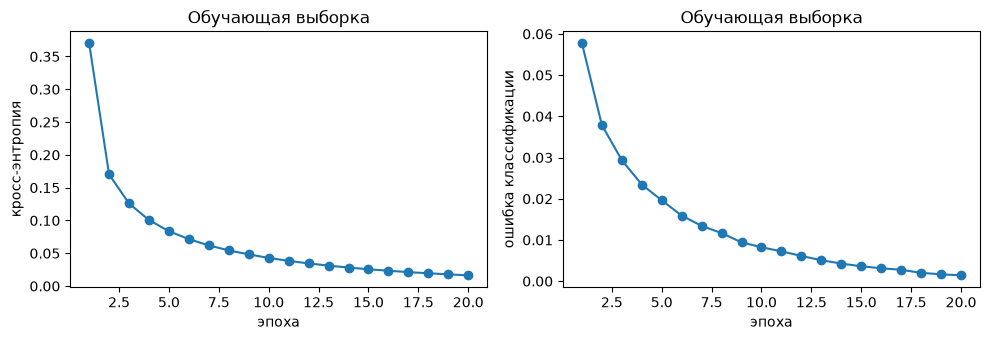

In [7]:
_, _, _, u_test = forward(X_test, W1, b1, W2, b2)
test_loss = cross_entropy(u_test, y_test)
test_error = classification_error(u_test, y_test)

print(f"тест: кросс-энтропия {test_loss:.4f}")
print(f"тест: ошибка классификации {test_error:.4f}")
print(f"тест: точность {1 - test_error:.4f}")

losses = [item[0] for item in history]
errors = [item[1] for item in history]
fig, axes = plt.subplots(1, 2, figsize=(10, 3.5))
axes[0].plot(range(1, EPOCHS + 1), losses, marker="o")
axes[0].set_xlabel("эпоха")
axes[0].set_ylabel("кросс-энтропия")
axes[0].set_title("Обучающая выборка")
axes[1].plot(range(1, EPOCHS + 1), errors, marker="o")
axes[1].set_xlabel("эпоха")
axes[1].set_ylabel("ошибка классификации")
axes[1].set_title("Обучающая выборка")
plt.tight_layout()
plt.show()


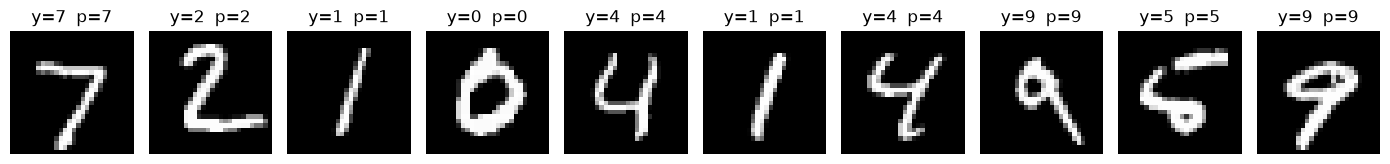

In [8]:
preview = np.arange(10)
fig, axes = plt.subplots(1, 10, figsize=(14, 2.2))
pred = u_test.argmax(axis=1)
for ax, i in zip(axes, preview):
    ax.imshow(test_images[i], cmap="gray")
    ax.set_title(f"y={int(y_test[i])}  p={int(pred[i])}")
    ax.axis("off")
plt.tight_layout()
plt.show()
